# Treino do detector de cicatriz (YOLOv8) no Google Colab — GPU

Notebook **self-contained** para treinar o detector de cicatriz da cesárea do projeto
*IA Multimodal para Saúde da Mulher* usando a **GPU gratuita do Colab**.

**O que ele faz**
1. Baixa o **AZH Wound completo** (`Train.zip` + `Test.zip`, ~28 MB, 730 imagens).
2. Converte para o formato **YOLOv8** com o *proxy* documentado no repositório:
   `N` (pele sem ferida) → `ferida_ok` (0) e `S` (ferida cirúrgica) → `ferida_alerta` (1),
   **1 caixa = imagem inteira** (margem de 2%).
3. Faz split **train/val** estratificado e gera o `data.yaml`.
4. Treina o `yolov8n` (ou `yolov8s`) em GPU e avalia (mAP@50, precisão, recall).
5. Gera `metrics.json` no **mesmo formato** de `ai-service/models/cicatriz/metrics.json`.
6. Exporta `best.pt` (+ ONNX) para colocar em `ai-service/models/cicatriz/`.

> **Antes de rodar:** menu **Runtime → Alterar o tipo de ambiente de execução → T4 GPU**.
>
> ⚠️ *Proxy honesto:* o AZH é uma base de **classificação** (não rotula infecção). Usar `N`/`S` é um
> proxy para validar o pipeline de **detecção**; para uso clínico real seriam necessárias imagens de
> cicatriz com caixas anotadas de verdade. Limitação já registrada em `data/README.md` e no relatório.

## 1) Verificar a GPU

Confirme que o Colab está com uma GPU ativa (T4 costuma bastar para o `yolov8n`/`yolov8s`).

In [1]:
!nvidia-smi

Sat Jun 27 17:47:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2) Instalar dependências

O `ultralytics` já traz o PyTorch com CUDA no ambiente do Colab.

In [2]:
%pip install -q 'ultralytics>=8.3'

import ultralytics

ultralytics.checks()

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.1/112.6 GB disk)


## 3) Baixar o AZH Wound completo (Train + Test)

Baixa os dois zips do repositório oficial e extrai. As imagens ficam organizadas em subpastas por
tipo de ferida (`N`, `S`, `BG`, `D`, `P`, `V`); usamos apenas `N` e `S`.

In [3]:
import urllib.request
import zipfile
from pathlib import Path

BASE = 'https://raw.githubusercontent.com/uwm-bigdata/wound-classification-using-images-and-locations/main/dataset'
ZIPS = ['Train.zip', 'Test.zip']
RAW = Path('/content/azh_raw')
RAW.mkdir(parents=True, exist_ok=True)

for nome in ZIPS:
    destino = RAW / nome
    if not destino.exists():
        print('Baixando', nome, '...')
        urllib.request.urlretrieve(f'{BASE}/{nome}', destino)
    with zipfile.ZipFile(destino) as zf:
        zf.extractall(RAW)
    print(nome, 'extraido')

subpastas = sorted({p.name for p in RAW.rglob('*') if p.is_dir()})
print('Subpastas de classe encontradas:', subpastas)

Baixando Train.zip ...
Train.zip extraido
Baixando Test.zip ...
Test.zip extraido
Subpastas de classe encontradas: ['BG', 'D', 'N', 'P', 'S', 'Test', 'Train', 'V', '__MACOSX']


## 4) Converter para YOLOv8 (proxy N/S) + split train/val

Mesmo *proxy* do script `scripts/data_prep/cicatriz_yolo.py`: cada imagem vira **uma caixa cobrindo
a imagem inteira** (margem de 2%), com a classe definida pela pasta (`N`→`ferida_ok`,
`S`→`ferida_alerta`). Aqui usamos **todas** as imagens (não só 3 por classe) e separamos 20% para
validação, de forma estratificada por classe.

In [5]:
import random
import shutil
from collections import Counter
from pathlib import Path

import yaml
from PIL import Image

RAW = Path('/content/azh_raw')
OUT = Path('/content/cicatriz_dataset')
CLASSES = {'N': 0, 'S': 1}          # pasta -> id (proxy do repo)
NOMES = {0: 'ferida_ok', 1: 'ferida_alerta'}
MARGEM = 0.02
VAL_FRAC = 0.2
random.seed(42)

if OUT.exists():
    shutil.rmtree(OUT)

amostras = []
for pasta in RAW.rglob('*'):
    # ignora a pasta __MACOSX dos zips (resource forks do macOS)
    if pasta.is_dir() and pasta.name in CLASSES and '__MACOSX' not in pasta.parts:
        cid = CLASSES[pasta.name]
        for img in pasta.iterdir():
            if img.name.startswith('._'):   # arquivos AppleDouble (nao sao imagens)
                continue
            if img.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                amostras.append((img, cid))

print('Total de imagens N/S:', len(amostras))
print('Por classe:', Counter(NOMES[c] for _, c in amostras))

por_classe = {0: [], 1: []}
for img, cid in amostras:
    por_classe[cid].append(img)

LADO = 1 - 2 * MARGEM   # caixa cobrindo (quase) toda a imagem

def escrever(img_path, cid, split, idx):
    img_dir = OUT / 'images' / split
    lbl_dir = OUT / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    nome = f'{NOMES[cid]}_{idx:05d}'
    try:
        with Image.open(img_path) as im:
            im.convert('RGB').save(img_dir / f'{nome}.jpg', 'JPEG', quality=92)
    except Exception as exc:
        print('pulando', img_path, exc)
        return False
    linha = f'{cid} 0.500000 0.500000 {LADO:.6f} {LADO:.6f}'
    (lbl_dir / f'{nome}.txt').write_text(linha + chr(10))
    return True

contagem = {'train': 0, 'val': 0}
for cid, imgs in por_classe.items():
    random.shuffle(imgs)
    n_val = max(1, int(len(imgs) * VAL_FRAC))
    val_imgs, train_imgs = imgs[:n_val], imgs[n_val:]
    for i, img in enumerate(train_imgs):
        if escrever(img, cid, 'train', i):
            contagem['train'] += 1
    for i, img in enumerate(val_imgs):
        if escrever(img, cid, 'val', i):
            contagem['val'] += 1

print('Amostras escritas:', contagem)

cfg = {
    'path': str(OUT),
    'train': 'images/train',
    'val': 'images/val',
    'nc': 2,
    'names': {0: 'ferida_ok', 1: 'ferida_alerta'},
}
(OUT / 'data.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
print(chr(10) + (OUT / 'data.yaml').read_text())

Total de imagens N/S: 264
Por classe: Counter({'ferida_alerta': 164, 'ferida_ok': 100})
Amostras escritas: {'train': 212, 'val': 52}

path: /content/cicatriz_dataset
train: images/train
val: images/val
nc: 2
names:
  0: ferida_ok
  1: ferida_alerta



## 5) Treinar o YOLOv8 (GPU)

`yolov8n` é rápido; troque `MODELO_BASE` para `'yolov8s.pt'` se quiser mais capacidade. Com GPU,
100 épocas neste dataset levam poucos minutos. `patience` faz *early stopping* se a validação parar
de melhorar.

In [6]:
from pathlib import Path

from ultralytics import YOLO

EPOCHS = 100            # 100-150 para um treino completo
IMGSZ = 640
BATCH = 16
MODELO_BASE = 'yolov8n.pt'   # ou 'yolov8s.pt'

modelo = YOLO(MODELO_BASE)
resultados = modelo.train(
    data='/content/cicatriz_dataset/data.yaml',
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=25,
    seed=42,
    project='runs_cicatriz',
    name='train',
    exist_ok=True,
)
save_dir = Path(resultados.save_dir)
print('Resultados salvos em:', save_dir)

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cicatriz_dataset/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pa

## 6) Avaliar e gerar `metrics.json`

Extrai mAP@50, precisão e recall do `results.csv` e o mAP por classe da validação — exatamente o
formato que `ai-service/app/cicatriz/treino.py` grava em `models/cicatriz/metrics.json`.

In [7]:
import json
from pathlib import Path

import pandas as pd

df = pd.read_csv(save_dir / 'results.csv')
df.columns = [c.strip() for c in df.columns]
ultima = df.iloc[-1]

def busca(*chaves):
    for chave in chaves:
        if chave in df.columns:
            return round(float(ultima[chave]), 4)
    return None

val = modelo.val(data='/content/cicatriz_dataset/data.yaml', imgsz=IMGSZ)
nomes = getattr(val, 'names', {}) or {}
mAP_por_classe = {}
try:
    for i, ap in zip(val.box.ap_class_index, val.box.maps, strict=False):
        mAP_por_classe[nomes.get(int(i), str(i))] = round(float(ap), 4)
except Exception:
    pass

metricas = {
    'mAP50': busca('metrics/mAP50(B)', 'metrics/mAP_0.5'),
    'precisao': busca('metrics/precision(B)', 'metrics/precision'),
    'recall': busca('metrics/recall(B)', 'metrics/recall'),
    'epocas': int(ultima.get('epoch', len(df))),
    'mAP_por_classe': mAP_por_classe,
}
print(json.dumps(metricas, indent=2, ensure_ascii=False))
Path('/content/metrics.json').write_text(json.dumps(metricas, indent=2, ensure_ascii=False))

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 930.0±700.9 MB/s, size: 14.9 KB)
val: Scanning /content/cicatriz_dataset/labels/val.cache... 52 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52/52 24.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.4it/s 1.7s0.6s
                   all         52         52      0.986      0.999      0.995      0.995
             ferida_ok         20         20          1      0.997      0.995      0.995
         ferida_alerta         32         32      0.972          1      0.995      0.995
Speed: 10.9ms preprocess, 10.8ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val
{
  "mAP50": 0.995,
  "precisao": 0.9916,
  "recall": 0.9869,
  "epocas": 41,
  "mAP_por_classe"

156

## 7) Visualizar resultados

Curvas de treino, matriz de confusão e exemplos de predição na validação.

results.png


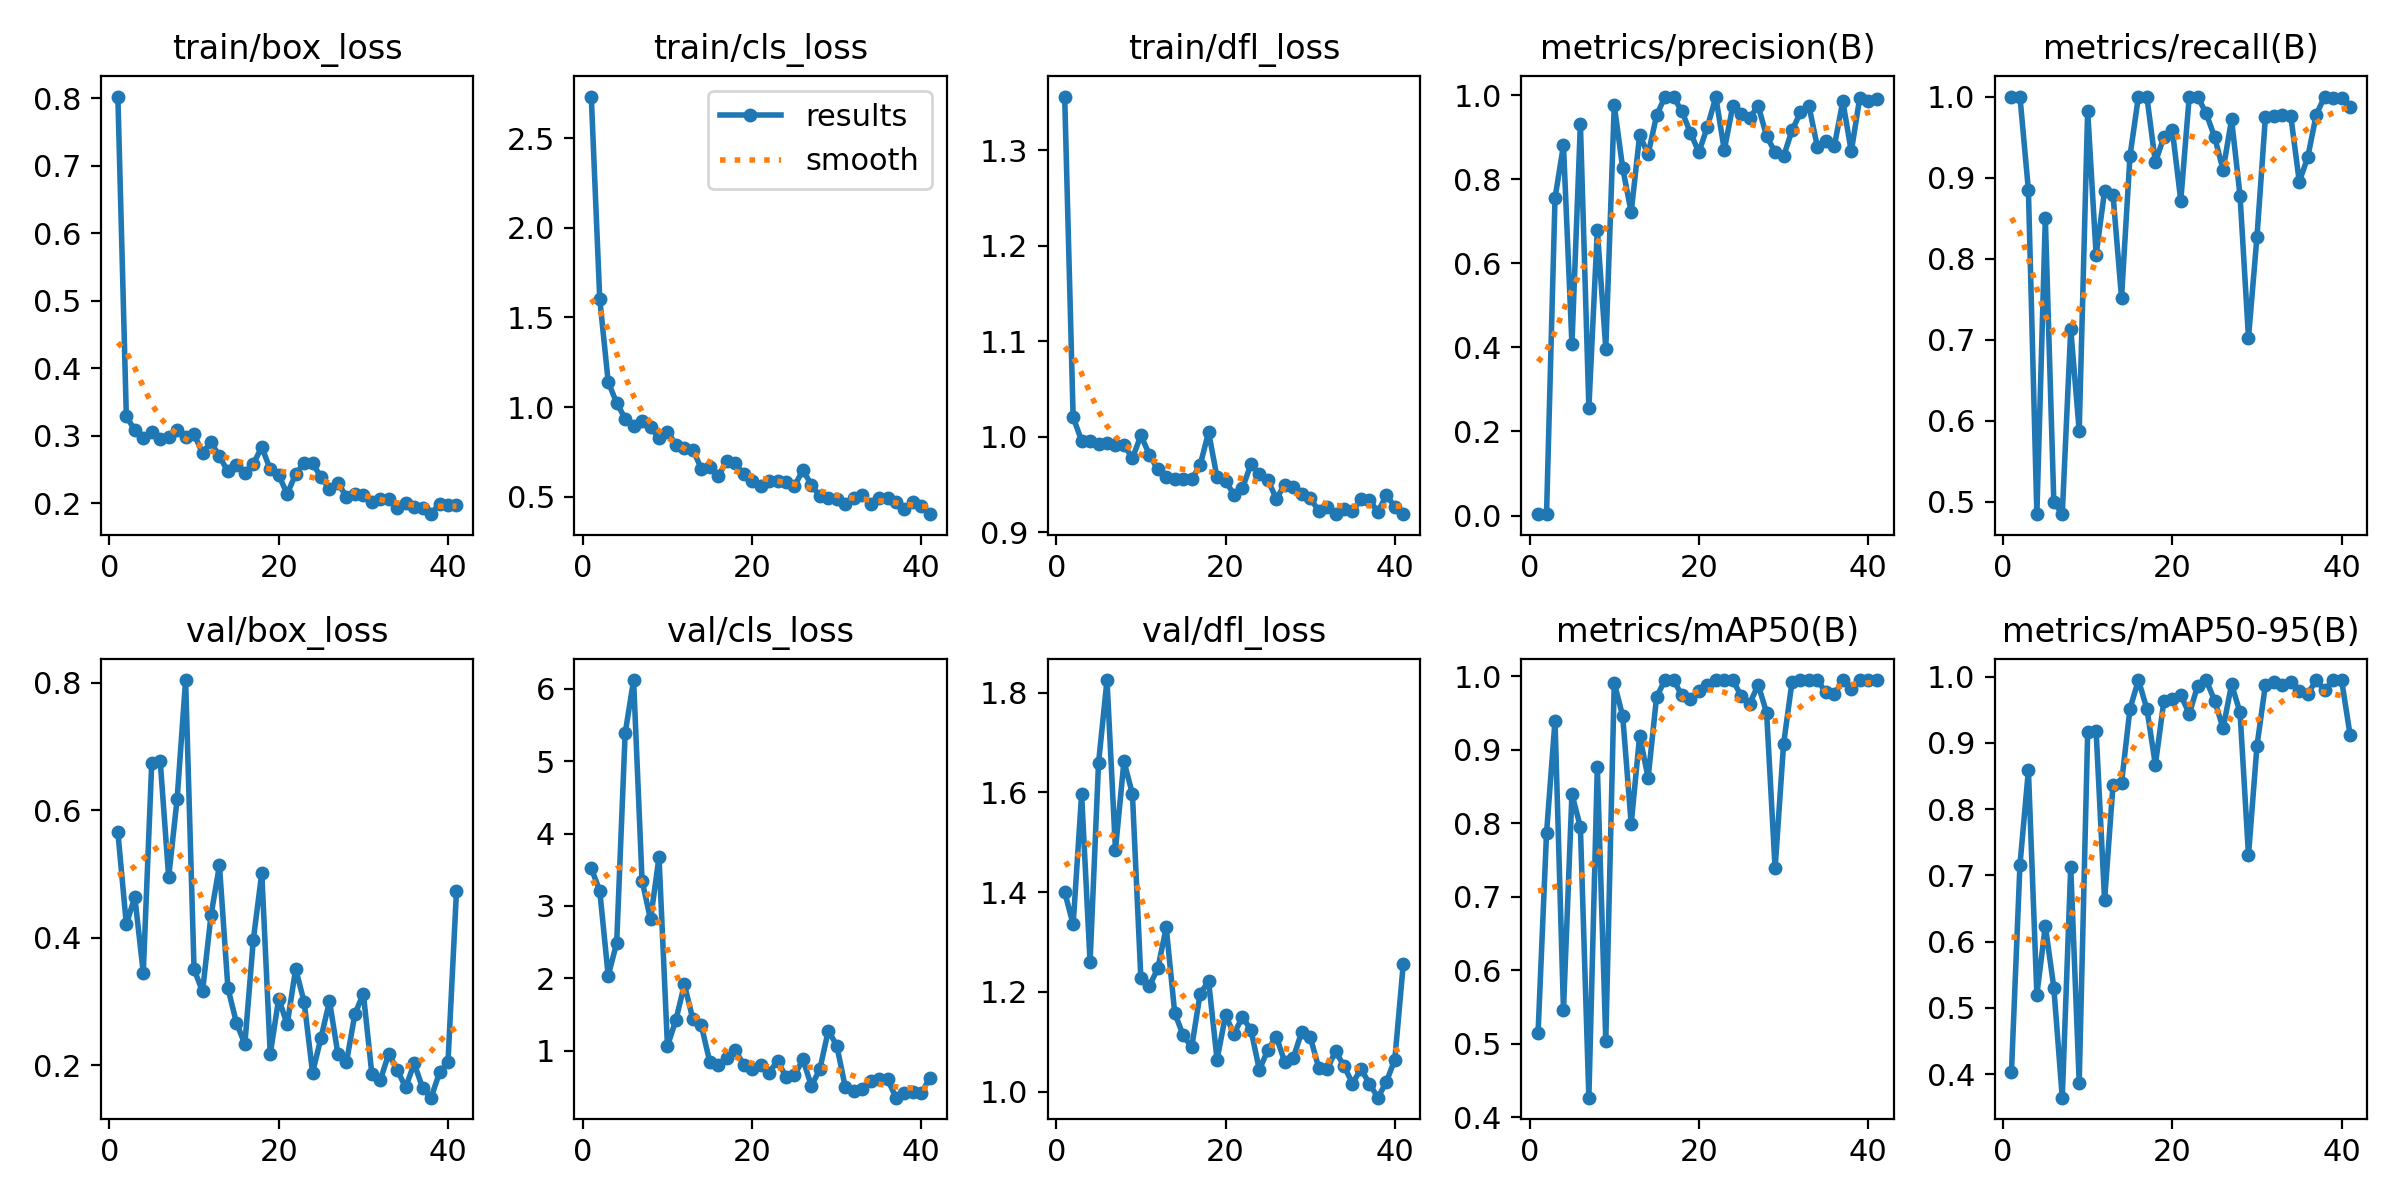

confusion_matrix.png


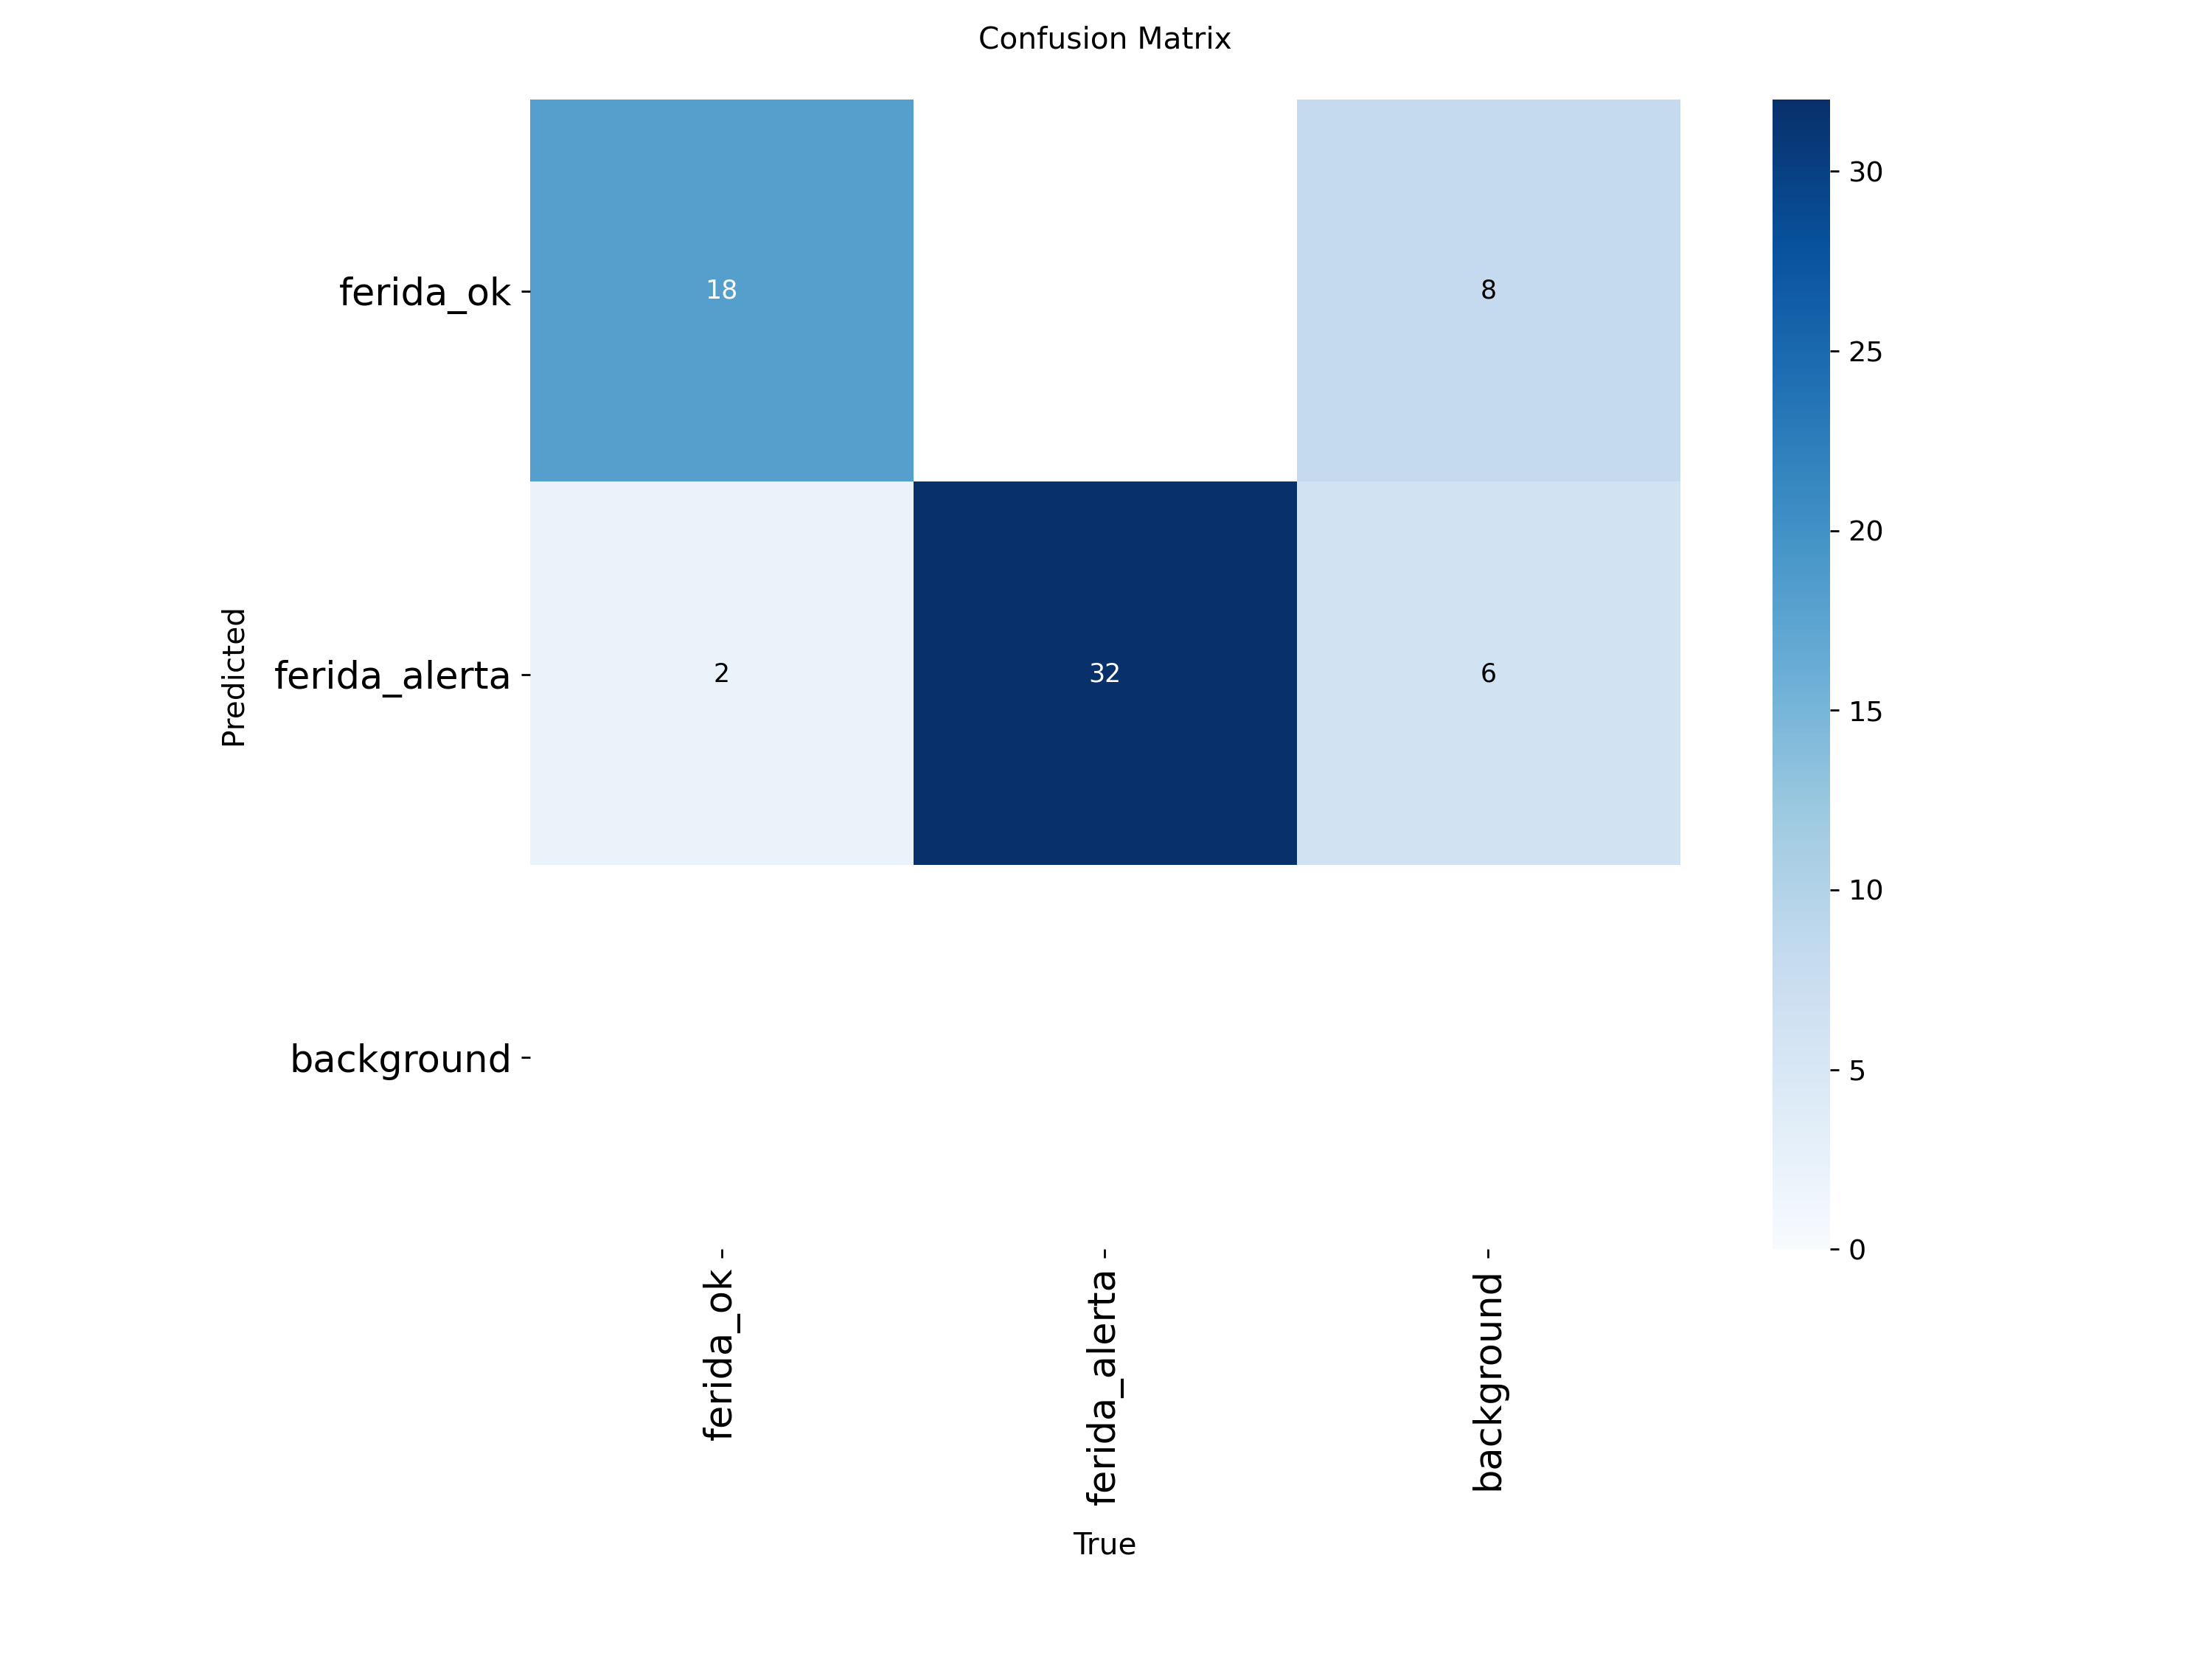

val_batch0_pred.jpg


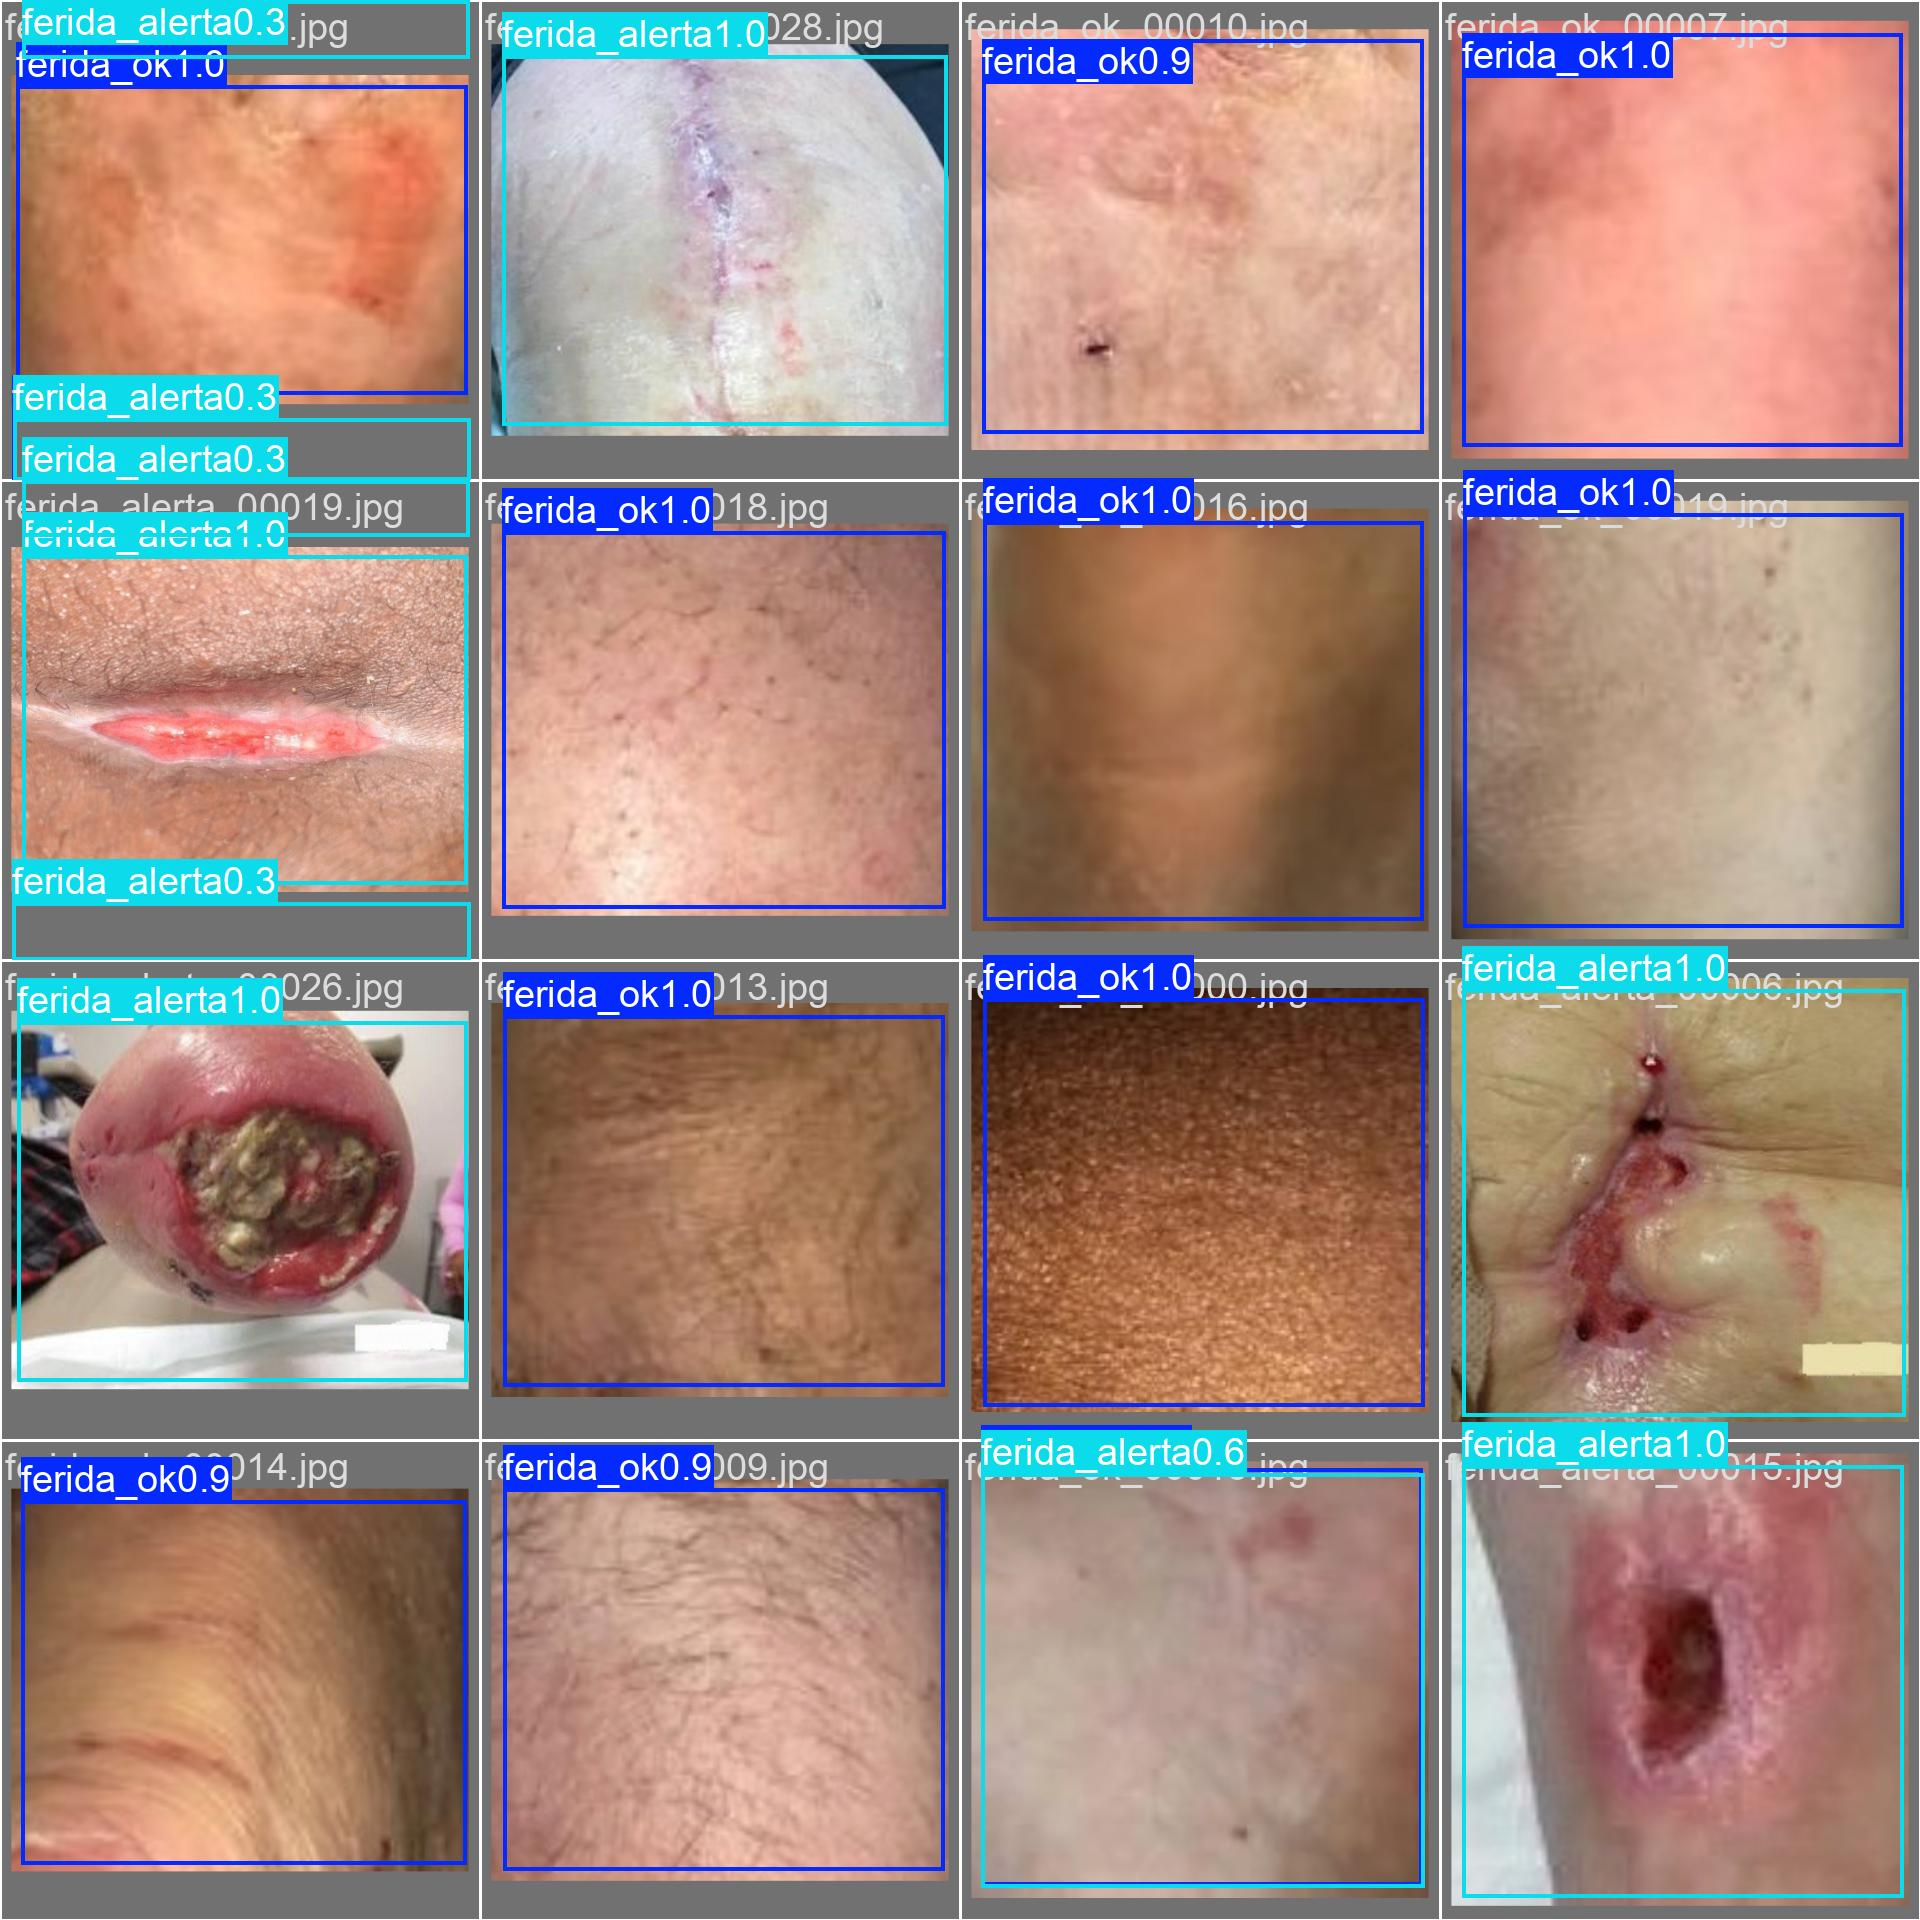

In [8]:
from IPython.display import Image as IPyImage
from IPython.display import display

for nome in ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'val_batch0_pred.jpg']:
    caminho = save_dir / nome
    if caminho.exists():
        print(nome)
        display(IPyImage(filename=str(caminho)))

## 8) Exportar e salvar os pesos

Copia `best.pt`, exporta ONNX (opcional) e **salva no Google Drive** (`MyDrive/cicatriz_yolo/`). O
Drive funciona tanto no Colab do navegador quanto pela **extensão do Colab no Cursor/VSCode**, onde o
runtime é remoto e `files.download()` não baixa para a máquina local. O download direto pelo navegador
fica como *fallback* comentado.

In [11]:
import shutil
from pathlib import Path

best = save_dir / 'weights' / 'best.pt'
shutil.copy2(best, '/content/best.pt')
print('best.pt:', Path('/content/best.pt').stat().st_size // 1024, 'KB')

# ONNX opcional (portabilidade; o ai-service aceita export ONNX)
try:
    caminho_onnx = modelo.export(format='onnx', imgsz=IMGSZ)
    print('ONNX exportado:', caminho_onnx)
except Exception as exc:
    print('Export ONNX falhou (opcional):', exc)

# --- Padrao: salvar no Google Drive ---
# Funciona tanto no Colab do navegador quanto via extensao do Colab no Cursor/VSCode
# (onde o runtime e remoto e files.download() nao baixa para a maquina local).
DRIVE_DIR = '/content/drive/MyDrive/cicatriz_yolo'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    destino = Path(DRIVE_DIR)
    destino.mkdir(parents=True, exist_ok=True)
    shutil.copy2('/content/best.pt', destino / 'best.pt')
    shutil.copy2('/content/metrics.json', destino / 'metrics.json')
    print('Salvo no Google Drive em:', destino)
    print('Abra drive.google.com, baixe best.pt + metrics.json')
    print('e copie para ai-service/models/cicatriz/.')
except Exception as exc:
    print('Mount do Drive indisponivel:', exc)
    print('Os arquivos estao na VM remota em /content/best.pt e /content/metrics.json.')

# --- Fallback (apenas Colab no navegador) ---
# Descomente se estiver rodando na aba do Colab no navegador (nao na extensao do Cursor):
# from google.colab import files
# files.download('/content/best.pt')
# files.download('/content/metrics.json')

Mounted at /content/drive
Salvo no Google Drive em: /content/drive/MyDrive/cicatriz_yolo
Abra drive.google.com, baixe best.pt + metrics.json e copie para ai-service/models/cicatriz/.


## 9) Como usar os pesos no repositório

Baixe `best.pt` + `metrics.json` da pasta `MyDrive/cicatriz_yolo/` em
[drive.google.com](https://drive.google.com) para o seu Mac e copie para `ai-service/models/cicatriz/`:

```bash
# a partir da raiz do repo (ajuste o caminho de origem para onde voce baixou)
cp ~/Downloads/best.pt      ai-service/models/cicatriz/best.pt
cp ~/Downloads/metrics.json ai-service/models/cicatriz/metrics.json
```

- `best.pt` é o peso treinado. **Não** é versionado no Git (política do repo: pesos ficam de fora),
  mas fica disponível localmente para a inferência (`ai-service/app/cicatriz/inferencia.py`).
- `metrics.json` **é** versionado e alimenta o §4.2 do relatório técnico.

> O notebook mantém o **proxy N/S** e o formato de `data.yaml`/classes **idêntico** ao de
> `ai-service/app/cicatriz/treino.py`, então o `best.pt` é *plug-and-play* com o serviço de IA.

### Próximos passos para sair do *proxy* (qualidade clínica)
- Substituir o proxy `N`/`S` por **imagens reais de cicatriz de cesárea** com `ferida_ok` vs
  `ferida_alerta` (infecção).
- Trocar a caixa "imagem inteira" por **bounding boxes anotadas** (ex.: Roboflow Annotate / LabelImg).
- Aumentar dados (mais imagens + *data augmentation* já embutido no YOLO) e considerar `yolov8s/m`.